In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras import regularizers
from tensorflow.keras.models import Model, load_model
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow
import seaborn as sns
sns.set_style('darkgrid')
from sklearn.metrics import confusion_matrix, classification_report
from IPython.core.display import display, HTML


In [2]:
import os
import shutil
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split

DATA_DIR = "/kaggle/input/datasets/shuvosingh/mri-syntheticdata/prepared_dataset"
CLEAN_DIR = "/kaggle/working/prepared_dataset_clean"
SEED = 42
IMG_EXTS = (".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff")

N_TOTAL = 5941
N_TRAIN = 4752
N_VAL = 594
N_TEST = 595

CLASS_KEYS = ("glioma", "meningioma", "notumor", "pituitary")

SYNTH_KEYWORDS = ("synthetic", "synth", "generated", "fake")

def is_synthetic(path):
    name = os.path.basename(path).lower()
    return any(k in name for k in SYNTH_KEYWORDS)

paths, labels = [], []
for root, dirs, files in os.walk(DATA_DIR):
    dirs.sort()
    key = os.path.basename(root).lower().replace("_", "").replace("-", "").replace(" ", "")
    if key in CLASS_KEYS:
        for f in sorted(files):
            if f.lower().endswith(IMG_EXTS):
                paths.append(os.path.join(root, f))
                labels.append(key)

paths = np.array(paths)
labels = np.array(labels)
classes = sorted(set(labels.tolist()))
class_count = len(classes)
print("Classes found:", classes)
print("Images available per class:", dict(sorted(Counter(labels.tolist()).items())))
print("Total available:", len(paths))
assert len(paths) >= N_TOTAL

all_syn = np.array([is_synthetic(p) for p in paths])
print("Synthetic found in dataset:", int(all_syn.sum()), "| Raw:", int((~all_syn).sum()))
assert all_syn.sum() > 0, "No synthetic image found - check SYNTH_KEYWORDS"

sel_p, _, sel_l, _ = train_test_split(paths, labels, train_size=N_TOTAL, stratify=labels, random_state=SEED)
orig_tr_p, rest_p, orig_tr_l, rest_l = train_test_split(sel_p, sel_l, train_size=N_TRAIN, stratify=sel_l, random_state=SEED)
va_p, te_p, va_l, te_l = train_test_split(rest_p, rest_l, test_size=N_TEST, stratify=rest_l, random_state=SEED)

train_quota = dict(Counter(orig_tr_l.tolist()))
held_out = set(va_p.tolist()) | set(te_p.tolist())

rng = np.random.RandomState(SEED)
tr_p, tr_l = [], []
for c in classes:
    pool = sorted(p for p, l in zip(paths, labels) if l == c and p not in held_out)
    syn_pool = [p for p in pool if is_synthetic(p)]
    raw_pool = [p for p in pool if not is_synthetic(p)]
    syn_pool = [syn_pool[i] for i in rng.permutation(len(syn_pool))]
    raw_pool = [raw_pool[i] for i in rng.permutation(len(raw_pool))]
    quota = train_quota[c]
    chosen = syn_pool[:quota]
    if len(chosen) < quota:
        chosen += raw_pool[:quota - len(chosen)]
    assert len(chosen) == quota, f"{c}: not enough images for train quota"
    tr_p += chosen
    tr_l += [c] * len(chosen)

tr_p, tr_l = np.array(tr_p), np.array(tr_l)
n_syn_train = sum(is_synthetic(p) for p in tr_p)
print(f"Train composition -> synthetic: {n_syn_train} | raw: {len(tr_p) - n_syn_train}")

if os.path.exists(CLEAN_DIR):
    shutil.rmtree(CLEAN_DIR)

rows = {"train": [], "val": [], "test": []}
for split, ps, ls in (("train", tr_p, tr_l), ("val", va_p, va_l), ("test", te_p, te_l)):
    for i, (p, c) in enumerate(zip(ps, ls)):
        dst_dir = os.path.join(CLEAN_DIR, split, str(c))
        os.makedirs(dst_dir, exist_ok=True)
        dst = os.path.join(dst_dir, f"{i}_{os.path.basename(p)}")
        shutil.copy2(p, dst)
        rows[split].append((dst, str(c)))

n = sum(len(v) for v in rows.values())
print("Total used:", n)
for split in ("train", "val", "test"):
    cnt = Counter(c for _, c in rows[split])
    print(f"{split}: {len(rows[split])} ({len(rows[split]) / n * 100:.1f}%)", dict(sorted(cnt.items())))

train_df = pd.DataFrame(rows["train"], columns=["filepaths", "labels"])
valid_df = pd.DataFrame(rows["val"],   columns=["filepaths", "labels"])
test_df  = pd.DataFrame(rows["test"],  columns=["filepaths", "labels"])

print('train size: ', len(train_df), '  valid size: ', len(valid_df), '   test size: ', len(test_df))
length = len(test_df)

Classes found: ['glioma', 'meningioma', 'notumor', 'pituitary']
Images available per class: {'glioma': 1871, 'meningioma': 1753, 'notumor': 2017, 'pituitary': 1794}
Total available: 7435
Synthetic found in dataset: 543 | Raw: 6892
Train composition -> synthetic: 456 | raw: 4296
Total used: 5941
train: 4752 (80.0%) {'glioma': 1196, 'meningioma': 1121, 'notumor': 1289, 'pituitary': 1146}
val: 594 (10.0%) {'glioma': 149, 'meningioma': 140, 'notumor': 161, 'pituitary': 144}
test: 595 (10.0%) {'glioma': 150, 'meningioma': 140, 'notumor': 162, 'pituitary': 143}
train size:  4752   valid size:  594    test size:  595


In [3]:
balance = train_df['labels'].value_counts()
print(balance)

labels
notumor       1289
glioma        1196
pituitary     1146
meningioma    1121
Name: count, dtype: int64


In [4]:
print('train size: ', len(train_df), '  valid size: ', len(valid_df), '   test size: ', len(test_df))


train size:  4752   valid size:  594    test size:  595


In [5]:
batch_size=16
def scalar(x):
    return x/127.5-1 # rescales pixels to range -1 to +1
trgen=tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=scalar, horizontal_flip=True)
train_gen=trgen.flow_from_dataframe(train_df, x_col='filepaths', y_col='labels', target_size=(224,224), class_mode='categorical',
                                   batch_size=batch_size, shuffle=True, seed=123)
tvgen=tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=scalar)
valid_gen=tvgen.flow_from_dataframe(valid_df, x_col='filepaths', y_col='labels', target_size=(224,224), class_mode='categorical',
                                   batch_size=batch_size, shuffle=False)
# determine test generator batch size and steps to go through the test set exactly once for predictions
test_batch_size=sorted([int(length/n) for n in range(1,length+1) if length % n ==0 and length/n<=batch_size],reverse=True)[0]
test_steps=int(length/test_batch_size)
test_gen=tvgen.flow_from_dataframe(test_df, x_col='filepaths', y_col='labels', target_size=(224,224), class_mode='categorical',
                                   batch_size=test_batch_size, shuffle=False)
test_labels=test_gen.labels

Found 4752 validated image filenames belonging to 4 classes.
Found 594 validated image filenames belonging to 4 classes.
Found 595 validated image filenames belonging to 4 classes.


In [6]:
def show_training_samples(gen):
    class_dict=gen.class_indices
    new_dict={}
    # make a new dictionary with keys and values reversed
    for key, value in class_dict.items(): # dictionary is now {numeric class label: string of class_name}
        new_dict[value]=key
    images,labels=next(gen) # get a sample batch from the generator
    plt.figure(figsize=(15, 18)) # Adjusted figure size for better display
    length=len(labels)
    if length<30:   #show maximum of 30 images
        r=length
    else:
        r=30
    for i in range(r):
        plt.subplot(6, 5, i + 1) # Changed grid to 6x5 to accommodate 30 subplots
        image=(images[i]+1 )/2 # scale images between 0 and 1 becaue pre-processor set them between -1 and +1
        plt.imshow(image)
        index=np.argmax(labels[i])
        class_name=new_dict[index]
        plt.title(class_name, color='blue', fontsize=16)
        plt.axis('off')
    plt.show()

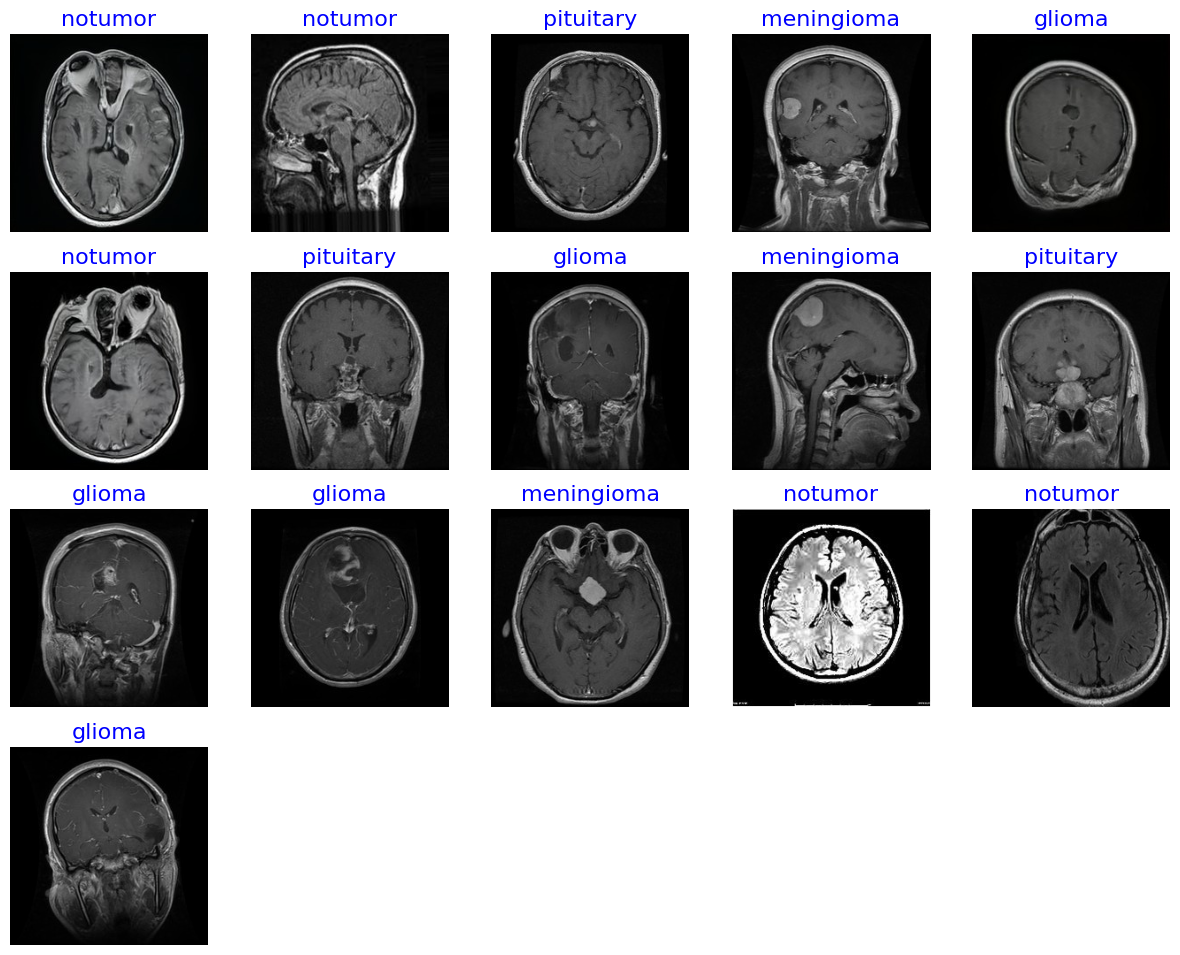

In [7]:
show_training_samples(train_gen)

In [8]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.optimizers import Adam

input_shape = (224, 224, 3)
class_count = len(classes)

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=input_shape
)

base_model.trainable = False

inputs = layers.Input(shape=input_shape)

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)

outputs = layers.Dense(
    class_count,
    activation='softmax'
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
    jit_compile=False
)

print("Model Summary:")
model.summary()

base_model.trainable = True

for layer in base_model.layers[:100]:
    layer.trainable = False

for layer in base_model.layers[100:]:
    layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
    jit_compile=False
)

print("\nFine-tuning Model Summary:")
model.summary()

I0000 00:00:1793071765.002052      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793071765.005729      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model Summary:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

...

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 3,845,472 (14.67 MB)

 Non-trainable params: 209,223 (817.28 KB)

In [9]:
'''
# Import necessary libraries
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, DenseNet169
from tensorflow.keras.optimizers import Adam

# Define input shape
input_shape = (224, 224, 3)

# Automatically detect number of classes
class_count = len(train_gen.class_indices)

print("Classes:", train_gen.class_indices)
print("Number of classes:", class_count)

# Load DenseNet169 model, EfficientNetB0, MobileNetV2
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=input_shape
)

# Freeze base model initially
base_model.trainable = False

# Build model
inputs = layers.Input(shape=input_shape)

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

outputs = layers.Dense(class_count, activation='softmax')(x)

# Final model
model = models.Model(inputs, outputs)

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Show model summary
model.summary()
'''

'\n# Import necessary libraries\nfrom tensorflow.keras import layers, models\nfrom tensorflow.keras.applications import MobileNetV2, EfficientNetB0, DenseNet169\nfrom tensorflow.keras.optimizers import Adam\n\n# Define input shape\ninput_shape = (224, 224, 3)\n\n# Automatically detect number of classes\nclass_count = len(train_gen.class_indices)\n\nprint("Classes:", train_gen.class_indices)\nprint("Number of classes:", class_count)\n\n# Load DenseNet169 model, EfficientNetB0, MobileNetV2\nbase_model = EfficientNetB0(\n    weights=\'imagenet\',\n    include_top=False,\n    input_shape=input_shape\n)\n\n# Freeze base model initially\nbase_model.trainable = False\n\n# Build model\ninputs = layers.Input(shape=input_shape)\n\nx = base_model(inputs, training=False)\n\nx = layers.GlobalAveragePooling2D()(x)\n\noutputs = layers.Dense(class_count, activation=\'softmax\')(x)\n\n# Final model\nmodel = models.Model(inputs, outputs)\n\n# Compile model\nmodel.compile(\n    optimizer=Adam(learning_ra

In [10]:
history = model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=15,
    verbose=1
)

Epoch 1/15


E0000 00:00:1793071787.587127      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


297/297 ━━━━━━━━━━━━━━━━━━━━ 54s 101ms/step - accuracy: 0.5364 - loss: 1.1446 - val_accuracy: 0.5522 - val_loss: 1.1710
Epoch 2/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 27s 90ms/step - accuracy: 0.6402 - loss: 0.9334 - val_accuracy: 0.7357 - val_loss: 0.7543
Epoch 3/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 27s 91ms/step - accuracy: 0.6761 - loss: 0.8460 - val_accuracy: 0.7609 - val_loss: 0.6591
Epoch 4/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 27s 92ms/step - accuracy: 0.6953 - loss: 0.7969 - val_accuracy: 0.7845 - val_loss: 0.6171
Epoch 5/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 28s 94ms/step - accuracy: 0.7096 - loss: 0.7513 - val_accuracy: 0.7997 - val_loss: 0.5742
Epoch 6/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 28s 94ms/step - accuracy: 0.7279 - loss: 0.7109 - val_accuracy: 0.8030 - val_loss: 0.5466
Epoch 7/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 28s 93ms/step - accuracy: 0.7414 - loss: 0.6740 - val_accuracy: 0.8266 - val_loss: 0.5241
Epoch 8/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 28s 95ms/step - accuracy: 0.7502 - loss: 0.6508 - val_accura

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def tr_plot(tr_data, start_epoch):
    # Plot the training and validation data
    tacc = tr_data.history['accuracy']
    tloss = tr_data.history['loss']
    vacc = tr_data.history['val_accuracy']
    vloss = tr_data.history['val_loss']

    Epoch_count = len(tacc) + start_epoch
    Epochs = list(range(start_epoch, Epoch_count))
    Epochs = [e + 1 for e in Epochs]

    index_loss = np.argmin(vloss)
    val_lowest = vloss[index_loss]
    index_acc = np.argmax(vacc)
    acc_highest = vacc[index_acc]

    tacc_pct = [a * 100 for a in tacc]
    vacc_pct = [a * 100 for a in vacc]

    train_color = '#1f77b4'   # teal/blue
    val_color = '#c2185b'     # crimson/magenta

    plt.style.use('default')
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

    ax = axes[0]
    ax.plot(Epochs, tacc_pct, color=train_color, marker='o', label='Train Accuracy')
    ax.plot(Epochs, vacc_pct, color=val_color, marker='s', label='Validation Accuracy')

    for x, y in zip(Epochs, tacc_pct):
        ax.annotate(f'{y:.3f}', (x, y), textcoords="offset points",
                    xytext=(0, -12), ha='center', fontsize=7, color=train_color)
    for x, y in zip(Epochs, vacc_pct):
        ax.annotate(f'{y:.3f}', (x, y), textcoords="offset points",
                    xytext=(0, 6), ha='center', fontsize=7, color=val_color)

    ax.set_title('Train vs Validation Accuracy (Exact values)')
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Accuracy (%)')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left')

    ax2 = axes[1]
    ax2.plot(Epochs, tloss, color=train_color, marker='o', label='Train Loss')
    ax2.plot(Epochs, vloss, color=val_color, marker='s', label='Validation Loss')

    for x, y in zip(Epochs, tloss):
        ax2.annotate(f'{y:.3f}', (x, y), textcoords="offset points",
                     xytext=(0, -12), ha='center', fontsize=7, color=train_color)
    for x, y in zip(Epochs, vloss):
        ax2.annotate(f'{y:.3f}', (x, y), textcoords="offset points",
                     xytext=(0, 6), ha='center', fontsize=7, color=val_color)

    ax2.set_title('Train vs Validation Loss (Exact values)')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss')
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

    print(f"Best validation loss: {val_lowest:.4f} at epoch {index_loss + 1 + start_epoch}")
    print(f"Best validation accuracy: {acc_highest*100:.3f}% at epoch {index_acc + 1 + start_epoch}")

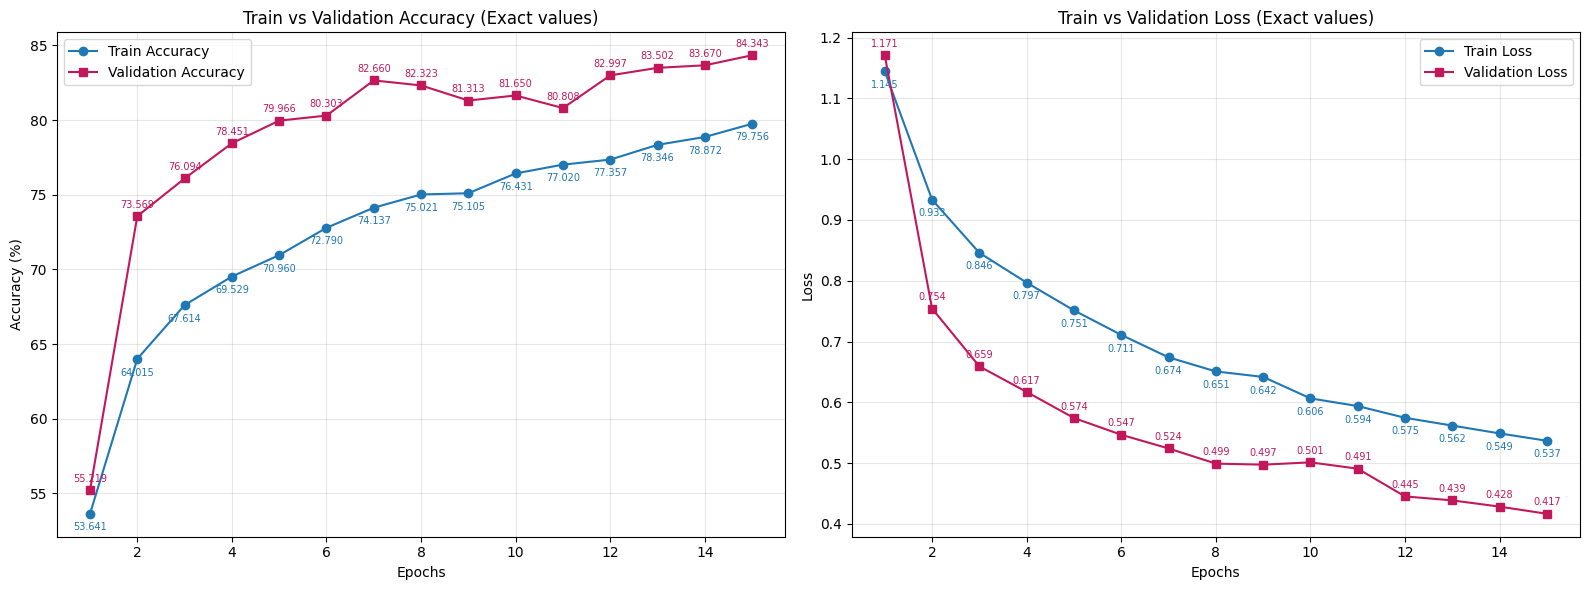

Best validation loss: 0.4166 at epoch 15
Best validation accuracy: 84.343% at epoch 15


In [12]:
tr_plot(history, 0)

85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step
Confusion Matrix
[[117  25   6   2]
 [ 24  89  18   9]
 [  2   7 146   7]
 [  7   6   4 126]]

Classification Report
              precision    recall  f1-score   support

      glioma       0.78      0.78      0.78       150
  meningioma       0.70      0.64      0.67       140
     notumor       0.84      0.90      0.87       162
   pituitary       0.88      0.88      0.88       143

    accuracy                           0.80       595
   macro avg       0.80      0.80      0.80       595
weighted avg       0.80      0.80      0.80       595



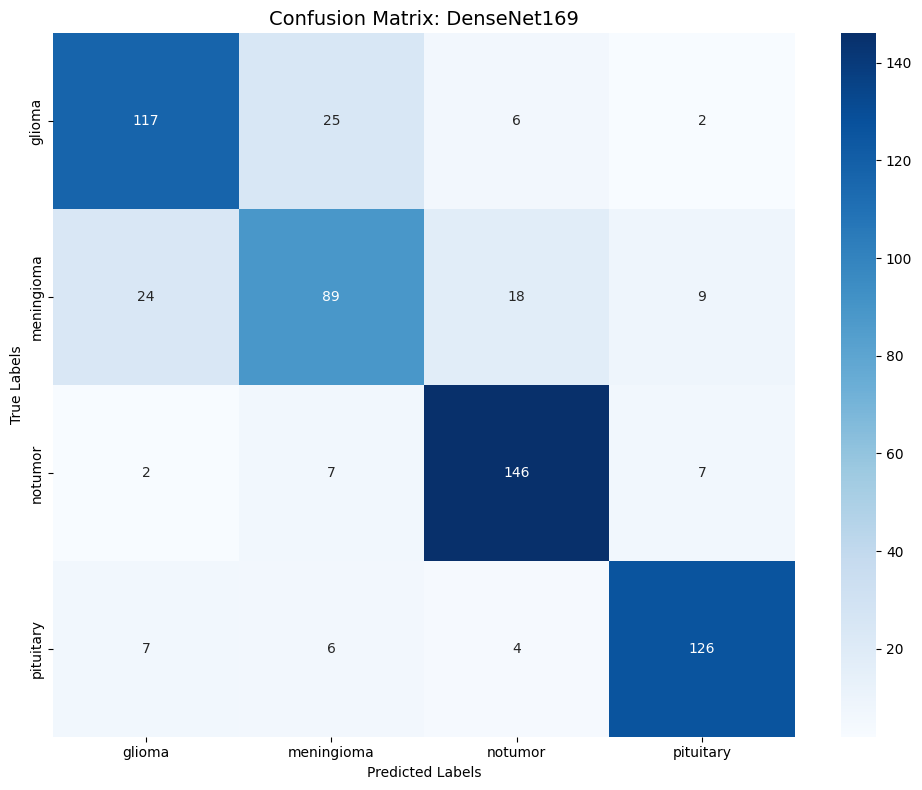

In [13]:
preds = model.predict(test_gen, verbose=1)

y_pred = np.argmax(preds, axis=1)

class_names = list(test_gen.class_indices.keys())

print('Confusion Matrix')

cm = confusion_matrix(test_labels, y_pred)

print(cm)

print('\nClassification Report')

print(
    classification_report(
        test_labels,
        y_pred,
        target_names=class_names
    )
)

# Plot Confusion Matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)

plt.title('Confusion Matrix: DenseNet169', fontsize=14)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')

plt.tight_layout()
plt.show()

# Parameters (Total & Trainable)

In [14]:
# Total Parameters
total_params = model.count_params()

# Trainable Parameters
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])

# Non-trainable Parameters
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Non-Trainable Parameters:", non_trainable_params)

Total Parameters: 4054695
Trainable Parameters: 3845472
Non-Trainable Parameters: 209223.0


# GMACs Calculation

In [15]:
!pip install keras-flops

In [16]:
import tensorflow as tf
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

# Create concrete function
full_model = tf.function(lambda x: model(x))
full_model = full_model.get_concrete_function(
    tf.TensorSpec([1, 224, 224, 3], tf.float32)
)

# Convert model to frozen graph
frozen_func = convert_variables_to_constants_v2(full_model)
graph_def = frozen_func.graph.as_graph_def()

# Calculate FLOPs
with tf.Graph().as_default() as graph:
    tf.graph_util.import_graph_def(graph_def, name='')

    run_meta = tf.compat.v1.RunMetadata()

    opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

    flops = tf.compat.v1.profiler.profile(
        graph=graph,
        run_meta=run_meta,
        cmd='op',
        options=opts
    )

# Total FLOPs
total_flops = flops.total_float_ops

# Convert FLOPs → GMACs
gmacs = total_flops / 1e9 / 2

print(f"Total FLOPs: {total_flops:,}")
print(f"GMACs: {gmacs:.4f}")

I0000 00:00:1793072221.075815      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1793072221.076948      49 single_machine.cc:376] Starting new session
I0000 00:00:1793072221.092243      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793072221.093877      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.

=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
op: The nodes are operation ker

# Latency

In [17]:
import time

# Take one batch
sample_batch = next(test_gen)[0]

# Single image
single_image = np.expand_dims(sample_batch[0], axis=0)

# Warmup
model.predict(single_image, verbose=0)

# Measure latency
start_time = time.time()

model.predict(single_image, verbose=0)

end_time = time.time()

latency = (end_time - start_time) * 1000

print(f"Latency: {latency:.2f} ms")

Latency: 86.22 ms


# Inference Time

In [18]:
start_time = time.time()

preds = model.predict(test_gen, verbose=1)

end_time = time.time()

inference_time = end_time - start_time

print(f"Inference Time: {inference_time:.2f} seconds")

85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
Inference Time: 1.74 seconds


# Throughput (FPS)
• FPS = images processed per second

In [19]:
num_images = len(test_df)

fps = num_images / inference_time

print(f"Throughput (FPS): {fps:.2f}")

Throughput (FPS): 341.84


# MCC (Matthews Correlation Coefficient)

In [20]:
from sklearn.metrics import matthews_corrcoef

# Predictions
y_pred = np.argmax(preds, axis=1)

# True labels
y_true = test_gen.labels

# MCC Score
mcc = matthews_corrcoef(y_true, y_pred)

print(f"MCC: {mcc:.4f}")

MCC: 0.7377


# Specificity

In [21]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_true, y_pred)

specificities = []

for i in range(len(cm)):
    
    TP = cm[i, i]
    
    FP = np.sum(cm[:, i]) - TP
    
    FN = np.sum(cm[i, :]) - TP
    
    TN = np.sum(cm) - (TP + FP + FN)
    
    specificity = TN / (TN + FP)
    
    specificities.append(specificity)

# Average specificity
avg_specificity = np.mean(specificities)

print(f"Specificity: {avg_specificity:.4f}")

Specificity: 0.9345


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


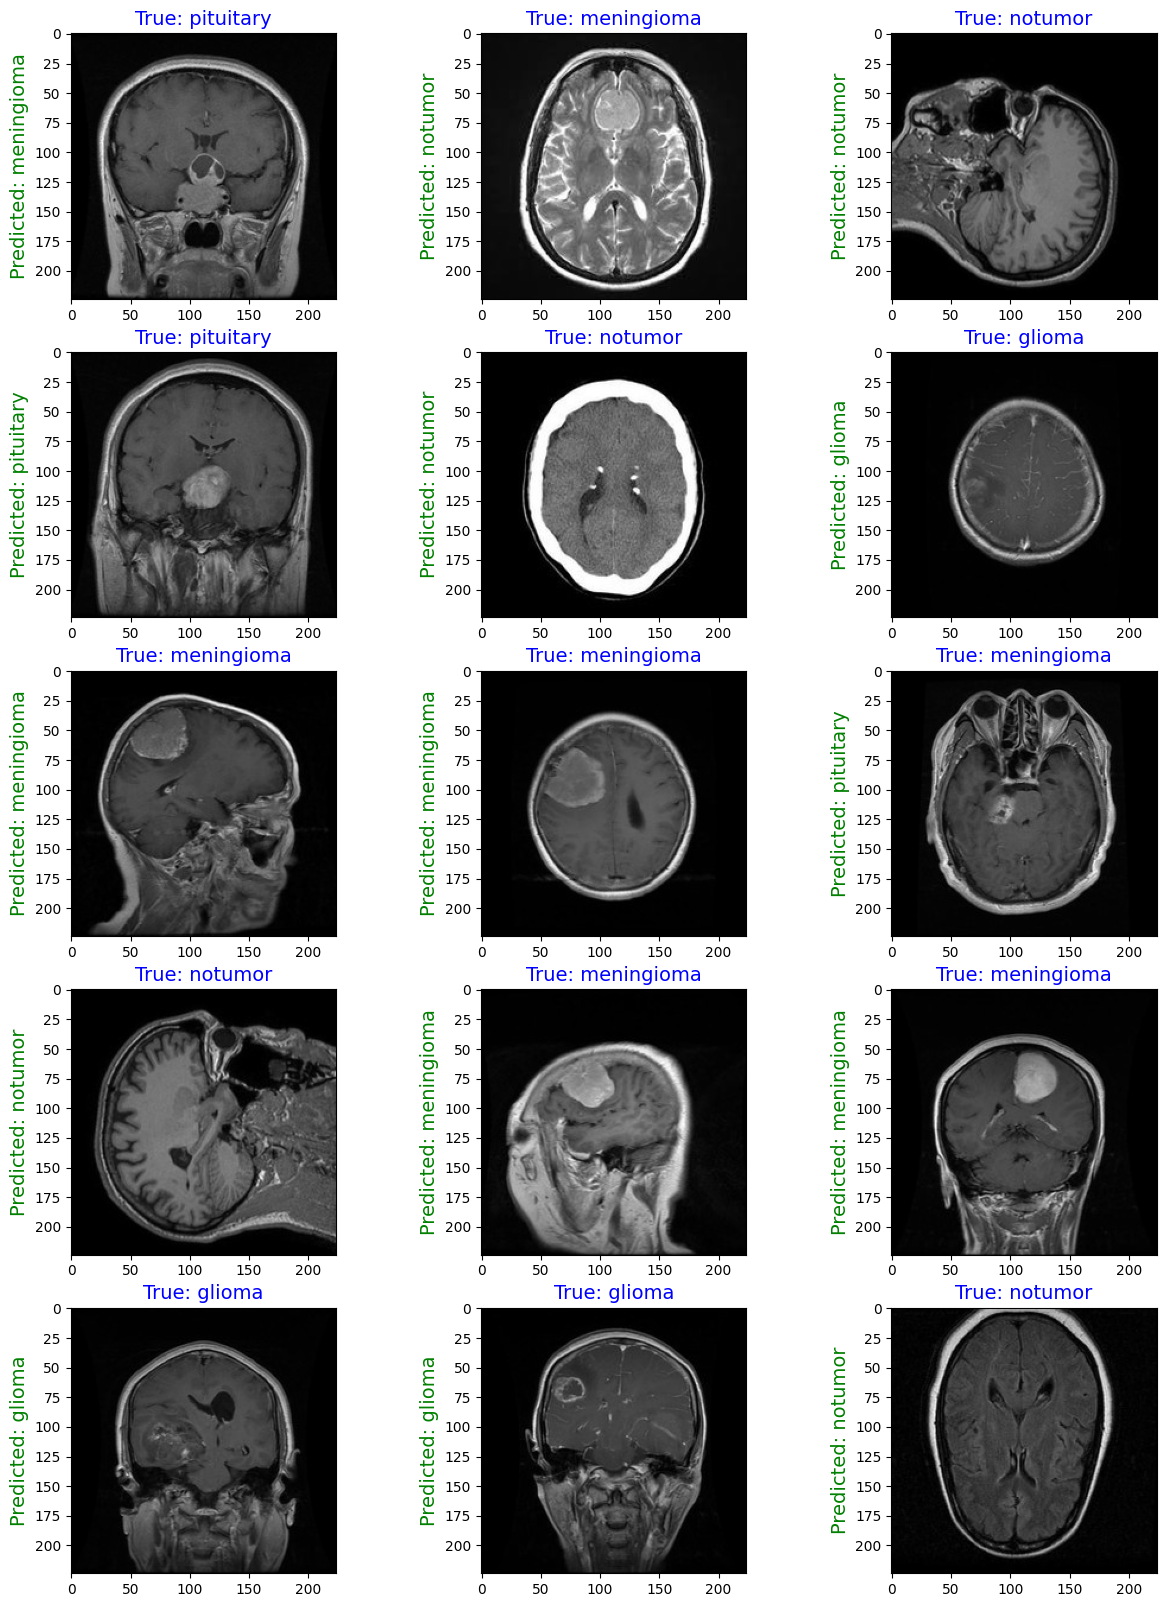

In [22]:
def print_images(gen):
    class_dict = gen.class_indices
    new_dict = {}
    # make a new dictionary with keys and values reversed
    for key, value in class_dict.items():
        new_dict[value] = key
    images, labels = next(gen)
    plt.figure(figsize=(15, 20))
    length = len(labels)
    if length < 15:
        r = length
    else:
        r = 15
    for i in range(r):
        plt.subplot(5, 3, i + 1)
        image = (images[i] + 1) / 2
        plt.imshow(image)
        index = np.argmax(labels[i])
        class_name = new_dict[index]
        pred = model.predict(np.expand_dims(images[i], axis=0))
        pred_index = np.argmax(pred)
        pred_class_name = new_dict[pred_index]
        plt.title(f"True: {class_name}", color='blue', fontsize=14) # Set true class title color to blue
        plt.ylabel(f"Predicted: {pred_class_name}", color='green', fontsize=14) # Set predicted class title color to green and moved it to xlabel for better visibility
        plt.axis('on')
    plt.show()

print_images(train_gen)